# Clasificación de noticias de la BBC con transformers
Miniproyecto 3 · MAIA-4213 Técnicas de Deep Learning

En este notebook se ajustan cinco modelos transformer preentrenados para clasificar artículos de la BBC en cinco categorías: business, entertainment, politics, sport y tech.

El enunciado habla de clasificación multi-etiqueta, pero cada artículo del dataset tiene una sola categoría y además se pide softmax. Por eso el problema se trata como multi-clase: una capa lineal de salida, softmax y entropía cruzada.

## Diseño experimental

Se comparan DistilBERT [3], BERT [1], RoBERTa [2], ELECTRA [4] y DeBERTa-v3 [5] con los mismos hiperparámetros y la misma partición estratificada 70/15/15. Cada modelo se entrena con las semillas 5, 42 y 45, que solo cambian la inicialización de la capa de salida, el dropout y el orden de los batches.

El mejor checkpoint de cada corrida y el modelo de referencia se eligen por F1 macro en validación. El test solo se usa para reportar.

El F1 macro en test se reporta con:

1. Media ± desviación estándar entre semillas e IC 95 % con t de Student (2 g.l.) [11], [12]. Mide la estabilidad del entrenamiento.
2. IC 95 % bootstrap con 5000 remuestreos del test [8], [9], [10]. Mide la incertidumbre por el tamaño del test.
3. Bootstrap pareado entre los 10 pares de modelos, con los mismos remuestreos y corrección de Holm (α = 0,05) [13]. Es la única prueba usada para decir que un modelo supera a otro.

En la sección 8 se cambia un solo hiperparámetro del modelo de referencia cada vez (longitud máxima, tasa de aprendizaje, weight decay o label smoothing) y se comparan los resultados en validación.

Fijar la semilla en GPU no garantiza resultados idénticos, así que cada corrida se guarda en `results/runs.pkl`. Si ya existe, se carga en lugar de volver a entrenar.

## Librerías y configuración

La primera celda instala lo necesario. La segunda importa las librerías y fija la configuración común a todos los experimentos. Con `DEBUG = True` todo corre en pocos minutos con dos modelos, una semilla y una época; sirve para probar el código, pero esos resultados no se reportan.

In [9]:
import subprocess, sys
paquetes = ['transformers>=4.46', 'datasets', 'accelerate', 'kagglehub', 'scikit-learn', 'seaborn', 'matplotlib',
            'scipy', 'sentencepiece', 'tiktoken', 'protobuf', 'truststore']
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *paquetes], check=True)
print('Paquetes instalados. Si alguno era nuevo, reiniciar el kernel antes de seguir.')

Paquetes instalados. Si alguno era nuevo, reiniciar el kernel antes de seguir.


In [ ]:
import truststore
truststore.inject_into_ssl()   # usa los certificados de Windows 
import os, re, gc, glob, time, shutil, pickle, textwrap, warnings
import numpy as np, pandas as pd, torch, transformers
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.special import softmax
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
warnings.filterwarnings('ignore')

DEBUG = True          # True: prueba rápida del código. Para el informe debe ir en False
RUN_ABLATION = True   # sección 8; se puede apagar para ahorrar tiempo

# Hiperparámetros comunes a todos los modelos
CFG = dict(
    seeds=[5, 42, 45],
    epochs=3, lr=2e-5, batch_size=16, max_len=256,
    weight_decay=0.01, label_smooth=0.1, warmup_frac=0.1,
    split_seed=42, val_frac=0.15, test_frac=0.15,
    n_boot=5000, alpha=0.05,
)
if DEBUG:
    CFG.update(seeds=[42], epochs=1, max_len=128, n_boot=200)

OUT_DIR, FIG_DIR = 'results', 'figs'
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)
RUNS_PATH = os.path.join(OUT_DIR, 'runs_debug.pkl' if DEBUG else 'runs.pkl')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Entrenando en', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU')
print('torch %s, transformers %s' % (torch.__version__, transformers.__version__))

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
                     'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9, 'legend.fontsize': 8})

# Nombre corto del modelo para tablas y figuras: 'google/electra-base-discriminator' -> 'electra'
def short(m):
    for s in ['-base-uncased', '-base-v2', '-base-discriminator', '-base']:
        m = m.replace(s, '')
    return m.split('/')[-1]

Entrenando en Quadro T2000
torch 2.14.1+cu126, transformers 5.22.2


## 1. Datos

Se usa el corpus de noticias de la BBC [6], que se descarga de Kaggle.

In [ ]:
# Descarga del dataset; se usa el CSV más grande, que trae el texto completo
import kagglehub
path = kagglehub.dataset_download('jacopoferretti/bbc-articles-dataset')
csv_files = sorted(glob.glob(os.path.join(path, '**', '*.csv'), recursive=True), key=os.path.getsize, reverse=True)
print(csv_files)
raw = pd.read_csv(csv_files[0])
print(raw.shape, raw.columns.tolist())

# Columnas de texto y de categoría (el dataset usa 'text' y 'labels')
TEXT_COL = 'text'
LABEL_COL = 'labels'

df = (raw[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates(subset=TEXT_COL)
      .rename(columns={TEXT_COL: 'text', LABEL_COL: 'label'}).reset_index(drop=True))
print('Quedan %d artículos después de quitar nulos y duplicados' % len(df))
print(df['label'].value_counts())

## 2. Exploración de datos

Antes de limpiar el texto se revisan dos cosas. La primera es el balance entre categorías, que justifica usar F1 macro y una partición estratificada. La segunda es la longitud de los artículos, que indica cuánto texto se pierde al cortar en 256 tokens. Esta figura no va en el informe.

Un artículo tiene en mediana 331 palabras; el 90 % tiene menos de 615 (rango: 89 a 4432)
La categoría más frecuente es sport (505 artículos) y la menos frecuente tech (347)


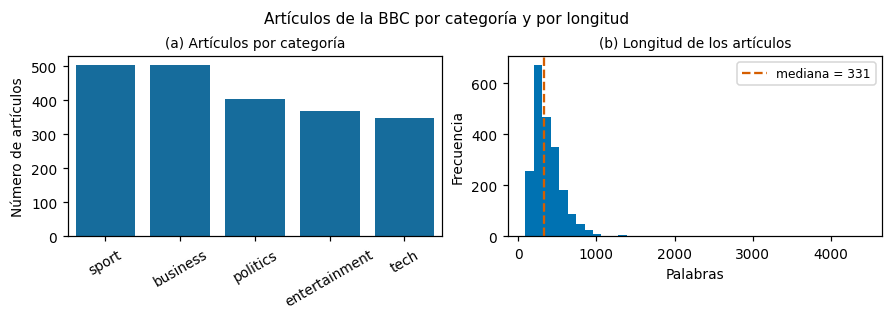

In [35]:
# Complementaria: exploración del dataset (antes de limpiar el texto)
n_words = df['text'].str.split().str.len()
vc = df['label'].value_counts()
print('Un artículo tiene en mediana %d palabras; el 90 %% tiene menos de %d (rango: %d a %d)'
      % (n_words.median(), np.percentile(n_words, 90), n_words.min(), n_words.max()))
print('La categoría más frecuente es %s (%d artículos) y la menos frecuente %s (%d)' % (vc.index[0], vc.iloc[0], vc.index[-1], vc.iloc[-1]))

fig, ax = plt.subplots(1, 2, figsize=(8, 2.8), constrained_layout=True)
sns.barplot(x=vc.index, y=vc.values, ax=ax[0], color='#0072B2')
ax[0].set_title('(a) Artículos por categoría'); ax[0].set_ylabel('Número de artículos'); ax[0].set_xlabel('')
ax[0].tick_params(axis='x', rotation=30)
ax[1].hist(n_words, bins=40, color='#0072B2')
ax[1].axvline(n_words.median(), color='#D55E00', ls='--', label='mediana = %d' % n_words.median())
ax[1].set_title('(b) Longitud de los artículos'); ax[1].set_xlabel('Palabras'); ax[1].set_ylabel('Frecuencia')
ax[1].legend()
fig.suptitle('Artículos de la BBC por categoría y por longitud', fontsize=10)
fig.savefig(FIG_DIR + '/comp_eda.png'); plt.show()

### Vocabulario y parecido entre categorías

Para ver qué tan separables son las categorías, cada artículo se representa con TF-IDF (sin stopwords en inglés). Se revisan las palabras con más peso en cada categoría y la similitud coseno entre los centroides de las categorías. Si dos categorías tienen centroides parecidos, es de esperar que los modelos las confundan más. Esta figura tampoco va en el informe.

Palabras con más peso TF-IDF en cada categoría:
  business       said, growth, economy, bank, market, company, year, sales, oil, mr
  entertainment  film, best, music, said, awards, award, band, year, festival, album
  politics       mr, said, labour, election, blair, party, government, brown, minister, howard
  sport          england, game, win, said, cup, match, team, players, injury, club
  tech           people, mobile, said, technology, users, games, software, phone, net, digital


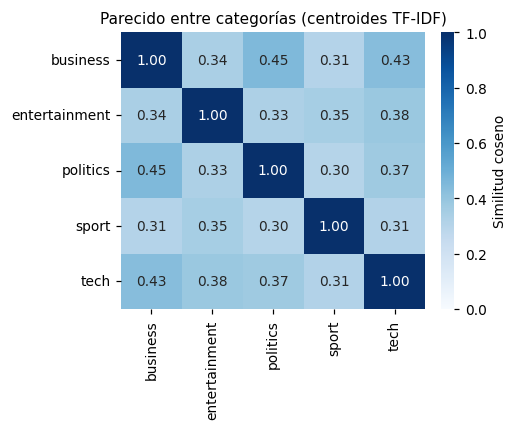

Las dos categorías más parecidas son business y politics (similitud 0.45)


In [36]:
# Complementaria: palabras más representativas y similitud entre categorías (TF-IDF)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf = TfidfVectorizer(stop_words='english', max_features=20000, min_df=3)
X = tfidf.fit_transform(df['text'])
vocab = np.array(tfidf.get_feature_names_out())
cats = sorted(df['label'].unique())

print('Palabras con más peso TF-IDF en cada categoría:')
for c in cats:
    media = np.asarray(X[(df['label'] == c).values].mean(axis=0)).ravel()
    print('  %-14s %s' % (c, ', '.join(vocab[media.argsort()[::-1][:10]])))

centros = np.vstack([np.asarray(X[(df['label'] == c).values].mean(axis=0)) for c in cats])
sim = pd.DataFrame(cosine_similarity(centros), index=cats, columns=cats)

fig, ax = plt.subplots(figsize=(4.6, 3.8), constrained_layout=True)
sns.heatmap(sim, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar_kws={'label': 'Similitud coseno'}, ax=ax)
ax.set_title('Parecido entre categorías (centroides TF-IDF)', fontsize=10)
fig.savefig(FIG_DIR + '/comp_similitud_categorias.png'); plt.show()

par = sim.where(~np.eye(len(cats), dtype=bool)).stack().idxmax()
print('Las dos categorías más parecidas son %s y %s (similitud %.2f)' % (par[0], par[1], sim.loc[par]))

## 3. Preprocesamiento y partición

### Limpieza del texto

La limpieza es corta, porque el texto de la BBC viene bastante limpio:

- Las entidades HTML se convierten en su carácter (`&#233;` pasa a `é`).
- Se quitan etiquetas HTML, URLs y correos.
- El titular viene en la primera línea; se le pone un punto para que no quede pegado a la primera frase.
- Los saltos de línea y los espacios repetidos quedan como un solo espacio.

No se quitan stopwords, signos ni mayúsculas, ni se hace stemming. Los transformers leen la frase completa y cada tokenizador hace su propia normalización, así que esos pasos solo quitarían información. Al final, las categorías se pasan a enteros y se cuenta cuántos tokens tiene cada artículo, para saber cuánto texto se pierde al truncar.

In [41]:
import html, unicodedata

# Pasos de limpieza: (nombre, patrón para contar los artículos que cambia, función)
PASOS = [
    ('Entidades HTML (&amp;, &quot;...)', r'&\w+;|&#\d+;',      html.unescape),
    ('Etiquetas HTML',                    r'<[^>]+>',            lambda t: re.sub(r'<[^>]+>', ' ', t)),
    ('URLs',                              r'http\S+|www\.\S+',   lambda t: re.sub(r'http\S+|www\.\S+', ' ', t)),
    ('Correos electrónicos',              r'\S+@\S+\.\w+',       lambda t: re.sub(r'\S+@\S+\.\w+', ' ', t)),
]

def clean_text(t):
    t = unicodedata.normalize('NFKC', t)
    for _, _, f in PASOS:
        t = f(t)
    # el titular va en la primera línea; se le agrega un punto para separarlo de la primera frase
    partes = t.strip().split('\n', 1)
    if len(partes) == 2 and not partes[0].rstrip().endswith(('.', '!', '?')):
        t = partes[0].rstrip() + '. ' + partes[1]
    return ' '.join(t.split())   # deja un solo espacio entre palabras

texto_original = df['text'].astype(str)
print('Artículos afectados por cada paso de limpieza:')
for nombre, patron, _ in PASOS:
    print('  %-38s %d' % (nombre, texto_original.str.contains(patron, regex=True).sum()))
print('  %-38s %d' % ('Titular separado de la primera frase', texto_original.str.strip().str.contains('\n').sum()))

df['text'] = texto_original.map(clean_text)
print('\nAntes:  ', repr(texto_original.iloc[0][:100]))
print('Después:', repr(df['text'].iloc[0][:100]))

# Categorías a enteros
labels = sorted(df['label'].unique())
K = len(labels)
label2id = {l: i for i, l in enumerate(labels)}
id2label = {i: l for l, i in label2id.items()}
df['label_id'] = df['label'].map(label2id)
print('Categorías (%d): %s' % (K, ', '.join(labels)))

# Cuántos artículos se truncan con cada longitud máxima (tokenizador de BERT como referencia)
tok_ref = AutoTokenizer.from_pretrained('bert-base-uncased')
n_tok = np.array([len(x) for x in tok_ref(df['text'].tolist(), truncation=False)['input_ids']])
print('Tokens por artículo (BERT): mediana %d, percentil 90 de %d' % (np.median(n_tok), np.percentile(n_tok, 90)))
for L in (128, 256, 512):
    print('  %.1f%% de los artículos pasa de %d tokens' % (100 * (n_tok > L).mean(), L))

Artículos afectados por cada paso de limpieza:
  Entidades HTML (&amp;, &quot;...)      25
  Etiquetas HTML                         0
  URLs                                   2
  Correos electrónicos                   0
  Titular separado de la primera frase   2127

Antes:   'Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.1'
Después: 'Ad sales boost Time Warner profit. Quarterly profits at US media giant TimeWarner jumped 76% to $1.1'
Categorías (5): business, entertainment, politics, sport, tech


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (573 > 512). Running this sequence through the model will result in indexing errors


Tokens por artículo (BERT): mediana 422, percentil 90 de 775
  100.0% de los artículos pasa de 128 tokens
  87.8% de los artículos pasa de 256 tokens
  35.7% de los artículos pasa de 512 tokens


### División

Los datos se dividen 70/15/15 (entrenamiento, validación y test) de forma estratificada, con la misma partición para todos los modelos y semillas. Cada modelo usa después su propio tokenizador, con truncamiento y padding por batch.

In [43]:
# 70/15/15 estratificado; la misma partición para todos los modelos y semillas
hold = CFG['val_frac'] + CFG['test_frac']
train_df, tmp_df = train_test_split(df, test_size=hold, stratify=df['label_id'], random_state=CFG['split_seed'])
val_df, test_df = train_test_split(tmp_df, test_size=CFG['test_frac'] / hold,
                                   stratify=tmp_df['label_id'], random_state=CFG['split_seed'])
if DEBUG:
    train_df, val_df, test_df = (train_df.sample(200, random_state=0),
                                 val_df.sample(80, random_state=0), test_df.sample(80, random_state=0))
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))
y_true = test_df['label_id'].values
print('Entrenamiento: %d artículos, validación: %d, test: %d' % (len(train_df), len(val_df), len(test_df)))

Entrenamiento: 200 artículos, validación: 80, test: 80


## 4. Arquitectura de los modelos

Los cinco modelos son encoders y clasifican de la misma manera. El encoder produce una representación de cada token, y la del primer token (`[CLS]` en BERT, `<s>` en RoBERTa) pasa por dropout, una capa lineal de 5 salidas y softmax. Esa capa lineal es lo único que empieza con pesos aleatorios; el resto del modelo viene preentrenado y se ajusta en el fine-tuning.

En tamaño son muy parecidos. BERT [1], RoBERTa [2], ELECTRA [4] y DeBERTa-v3 [5] tienen 12 capas, dimensión oculta de 768 y 12 cabezas de atención. DistilBERT [3] mantiene la dimensión y las cabezas, pero tiene solo 6 capas, porque se obtiene destilando BERT: se entrena para reproducir sus salidas con la mitad de la profundidad.

Lo que más los diferencia es el preentrenamiento. BERT aprende a predecir palabras ocultas y a decidir si dos frases van seguidas. RoBERTa usa la misma arquitectura, pero se preentrena con más datos y sin la tarea de frases seguidas. ELECTRA aprende a detectar qué palabras de una frase fueron reemplazadas, así que aprovecha todo el texto y no solo las palabras ocultas. DeBERTa-v3 se preentrena como ELECTRA y además cambia la atención, que trata por separado el contenido de cada palabra y su posición.

El tokenizador también cambia: BERT, DistilBERT y ELECTRA usan WordPiece, RoBERTa usa BPE a nivel de bytes y DeBERTa-v3 usa SentencePiece. La celda siguiente descarga la configuración de cada modelo desde Hugging Face para comprobar estos valores.

### ¿Por qué estas arquitecturas?

Para clasificar un artículo completo sirve más un encoder bidireccional, que ve el contexto a ambos lados de cada palabra, que un modelo generativo que lee de izquierda a derecha. Con unos 1500 artículos de entrenamiento tampoco tiene sentido entrenar desde cero, así que se parte de modelos preentrenados.

BERT sirve como punto de partida. DistilBERT muestra cuánto se pierde con un modelo más pequeño y rápido. Como RoBERTa y ELECTRA tienen el mismo tamaño que BERT, cualquier diferencia con BERT se puede atribuir al preentrenamiento. DeBERTa-v3 permite ver si además ayuda cambiar la atención.

DeBERTa-v3 tiene unos 184 millones de parámetros, más que los demás, aunque tiene el mismo número de capas. La diferencia está en los embeddings, porque su vocabulario supera los 128 000 tokens. La tabla de resultados de la sección 6 muestra el número real de parámetros de cada modelo.

In [18]:
# Modelos que se comparan (identificadores de Hugging Face)
MODELOS = ['distilbert-base-uncased',
           'bert-base-uncased',
           'roberta-base',
           'google/electra-base-discriminator',
           'microsoft/deberta-v3-base']
CFG['models'] = MODELOS[:2] if DEBUG else MODELOS   # en DEBUG solo se entrenan los dos primeros

# Capas, dimensión y cabezas de cada modelo, leídas de Hugging Face (solo la configuración, sin los pesos)
from transformers import AutoConfig
filas = []
for m in MODELOS:
    c = AutoConfig.from_pretrained(m)
    filas.append({'Modelo': short(m), 'Capas': c.num_hidden_layers, 'Dim. oculta': c.hidden_size,
                  'Cabezas': c.num_attention_heads, 'Vocabulario': c.vocab_size})
display(pd.DataFrame(filas).set_index('Modelo'))

,Capas,Dim. oculta,Cabezas,Vocabulario
Modelo,,,,
distilbert,6,768,12,30522
bert,12,768,12,30522
roberta,12,768,12,50265
electra,12,768,12,30522
deberta-v3,12,768,12,128100


## 5. Entrenamiento

Cada modelo se carga con `AutoModelForSequenceClassification`, que agrega al encoder la capa de 5 salidas descrita arriba (en BERT es `BertForSequenceClassification`). Todos usan los mismos hiperparámetros: lr de 2e-5, 3 épocas, batch efectivo de 16, AdamW, warmup del 10 % con decaimiento lineal, fp16 y un máximo de 256 tokens. El lr no se ajusta por modelo para no favorecer a ninguno, y eso queda como limitación.

Con unos 1500 artículos de entrenamiento hay riesgo de sobreajuste. Para reducirlo se usa un lr bajo y solo 3 épocas, weight decay de 0,01 con AdamW [15], label smoothing de 0,1 [14] y el dropout que traen los modelos [16]. Además se guarda el checkpoint de la época con mejor F1 macro en validación, que hace las veces de early stopping. Después del entrenamiento se grafican la pérdida y la accuracy de validación por época; la sección 6 revisa el sobreajuste con más detalle y la sección 8 compara el weight decay y el label smoothing contra no usarlos.

In [19]:
# Corridas ya hechas: se cargan de disco para no repetir el entrenamiento
RUNS = pickle.load(open(RUNS_PATH, 'rb')) if os.path.exists(RUNS_PATH) else {}
n_old = len(RUNS)
RUNS = {k: v for k, v in RUNS.items() if len(k) == 6}   # las de versiones viejas del código tenían otra clave
print('%d corridas cargadas de disco' % len(RUNS) + (' (%d descartadas por formato antiguo)' % (n_old - len(RUNS)) if n_old > len(RUNS) else ''))

def save_runs():
    pickle.dump(RUNS, open(RUNS_PATH, 'wb'))

def compute_metrics(eval_pred):
    logits, y = eval_pred
    p = np.argmax(logits, axis=-1)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(y, p), 'precision_macro': pr, 'recall_macro': rc, 'f1_macro': f1}

def to_ds(tok, d, max_len):
    ds = Dataset.from_dict({'text': d['text'].tolist(), 'labels': d['label_id'].tolist()})
    return ds.map(lambda b: tok(b['text'], truncation=True, max_length=max_len),
                  batched=True, remove_columns=['text'])

# Entrena un modelo con una semilla y una configuración, evalúa en test y guarda el resultado
def run_one(model_name, seed, max_len, lr, wd=None, ls=None):
    wd = CFG['weight_decay'] if wd is None else wd
    ls = CFG['label_smooth'] if ls is None else ls
    key = (model_name, seed, max_len, lr, wd, ls)
    if key in RUNS:
        return RUNS[key]
    set_seed(seed)
    out_dir = os.path.join(OUT_DIR, 'tmp_ckpt')
    model = trainer = None
    try:
        tok = AutoTokenizer.from_pretrained(model_name)
        tr, va, te = (to_ds(tok, d, max_len) for d in (train_df, val_df, test_df))
        model = AutoModelForSequenceClassification.from_pretrained(
            model_name, num_labels=K, id2label=id2label, label2id=label2id)
        # con 512 tokens no cabe un batch de 16 en memoria: se usan 8 y se acumula el gradiente de dos pasos
        micro = CFG['batch_size'] if max_len <= 256 else CFG['batch_size'] // 2
        steps = int(np.ceil(len(train_df) / CFG['batch_size'])) * CFG['epochs']
        args = TrainingArguments(
            output_dir=out_dir, num_train_epochs=CFG['epochs'], learning_rate=lr,
            per_device_train_batch_size=micro, gradient_accumulation_steps=CFG['batch_size'] // micro,
            per_device_eval_batch_size=32, weight_decay=wd, label_smoothing_factor=ls,
            warmup_steps=int(CFG['warmup_frac'] * steps),
            eval_strategy='epoch', save_strategy='epoch', save_total_limit=1,
            load_best_model_at_end=True, metric_for_best_model='f1_macro',
            logging_strategy='epoch', disable_tqdm=True, report_to='none',
            fp16=(DEVICE == 'cuda'), seed=seed, data_seed=seed)
        trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=va,
                          processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                          compute_metrics=compute_metrics)
        t0 = time.time(); trainer.train(); train_s = time.time() - t0
        t0 = time.time(); out = trainer.predict(te); infer_ms = (time.time() - t0) / len(test_df) * 1000
        logits = out.predictions
        preds = logits.argmax(-1)
        pr, rc, f1, _ = precision_recall_fscore_support(y_true, preds, average='macro', zero_division=0)
        pcf1 = precision_recall_fscore_support(y_true, preds, labels=list(range(K)), zero_division=0)[2]
        rec = dict(model=model_name, seed=seed, max_len=max_len, lr=lr, wd=wd, ls=ls,
                   accuracy=accuracy_score(y_true, preds), precision_macro=pr, recall_macro=rc, f1_macro=f1,
                   params_m=sum(p.numel() for p in model.parameters()) / 1e6,
                   train_s=train_s, infer_ms=infer_ms,
                   per_class_f1=pcf1, preds=preds, probs=softmax(logits, axis=-1),
                   train_loss=[h['loss'] for h in trainer.state.log_history if 'loss' in h],
                   history=[{'epoch': h['epoch'], 'eval_f1_macro': h['eval_f1_macro'], 'eval_loss': h['eval_loss'],
                             'eval_accuracy': h['eval_accuracy']}
                            for h in trainer.state.log_history if 'eval_f1_macro' in h])
        RUNS[key] = rec
        save_runs()
        return rec
    finally:
        del model, trainer
        gc.collect()
        if DEVICE == 'cuda':
            torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

8 corridas cargadas de disco


In [20]:
# Las 5 x 3 corridas principales. Si una falla (por ejemplo, sin memoria en la GPU), se sigue con la siguiente
FAILED = []
for m in CFG['models']:
    for s in CFG['seeds']:
        try:
            r = run_one(m, s, CFG['max_len'], CFG['lr'])
            print('%-12s semilla %2d   accuracy %.4f   F1 %.4f   %4.0f s' % (short(m), s, r['accuracy'], r['f1_macro'], r['train_s']))
        except Exception as e:
            FAILED.append((m, s, repr(e)[:200]))
            print('Falló %s con semilla %d: %s' % (short(m), s, repr(e)[:200]))
print('Todas las corridas terminaron' if not FAILED else 'Corridas con error: %s' % FAILED)

distilbert   semilla 42   accuracy 0.5250   F1 0.3782     25 s
bert         semilla 42   accuracy 0.4875   F1 0.3344     48 s
Todas las corridas terminaron


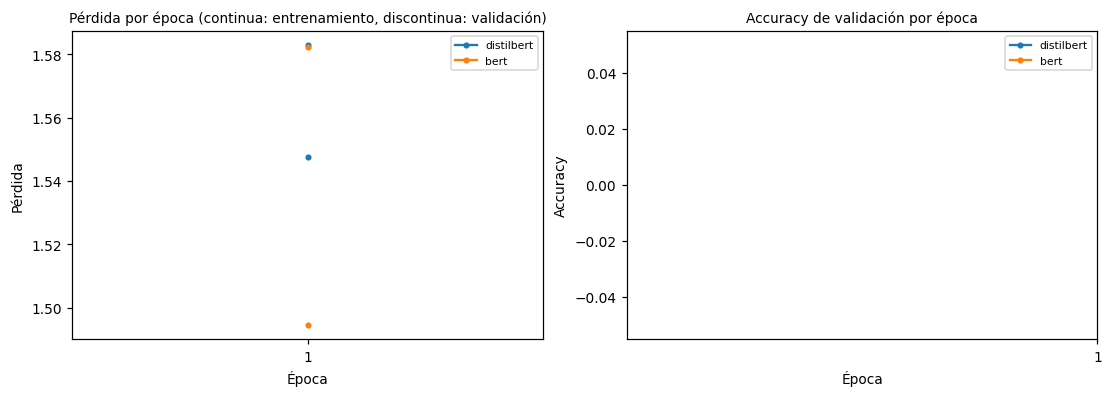

In [44]:
# Complementaria: pérdida y accuracy de validación por época, promedio de las semillas
E = CFG['epochs']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for m in CFG['models']:
    ks = [k for k in RUNS if k[0] == m and k[1] in CFG['seeds'] and k[2] == CFG['max_len'] and k[3] == CFG['lr']
          and k[4] == CFG['weight_decay'] and k[5] == CFG['label_smooth']]
    if not ks:
        continue
    tr = np.mean([RUNS[k]['train_loss'][:E] for k in ks], axis=0)
    va = np.mean([[h['eval_loss'] for h in RUNS[k]['history']] for k in ks], axis=0)
    acc = np.mean([[h.get('eval_accuracy', np.nan) for h in RUNS[k]['history']] for k in ks], axis=0)
    ep = np.arange(1, len(va) + 1)
    linea, = ax[0].plot(ep[:len(tr)], tr, marker='o', ms=3, label=short(m))
    ax[0].plot(ep, va, marker='o', ms=3, ls='--', color=linea.get_color())
    ax[1].plot(ep, acc, marker='o', ms=3, color=linea.get_color(), label=short(m))

ax[0].set_title('Pérdida por época (continua: entrenamiento, discontinua: validación)', fontsize=9)
ax[0].set_xlabel('Época'); ax[0].set_ylabel('Pérdida'); ax[0].legend(fontsize=7)
ax[1].set_title('Accuracy de validación por época', fontsize=9)
ax[1].set_xlabel('Época'); ax[1].set_ylabel('Accuracy'); ax[1].legend(fontsize=7)
for a in ax:
    a.set_xticks(range(1, E + 1))
fig.savefig(FIG_DIR + '/comp_curvas_entrenamiento.png'); plt.show()


## 6. Resultados cuantitativos

Todas las métricas son sobre test y se promedian entre las semillas. El orden de los modelos en tablas y figuras sale del F1 macro en validación.

In [22]:
# Corridas principales de un modelo (configuración base y semillas de CFG)
def main_keys(m):
    return [k for k in RUNS if k[0] == m and k[2] == CFG['max_len'] and k[3] == CFG['lr']
            and k[4] == CFG['weight_decay'] and k[5] == CFG['label_smooth'] and k[1] in CFG['seeds']]

def runs_df(max_len=None, lr=None, models=None, seeds=None, wd=None, ls=None):
    rows = []
    for (m, s, ml, l, w, sm), r in RUNS.items():
        if ((max_len is None or ml == max_len) and (lr is None or l == lr)
                and (wd is None or w == wd) and (ls is None or sm == ls)
                and (models is None or m in models) and (seeds is None or s in seeds)):
            d = {k: v for k, v in r.items() if k not in ('preds', 'probs', 'per_class_f1', 'history')}
            d['val_f1'] = max(h['eval_f1_macro'] for h in r['history'])   # mejor época en validación
            rows.append(d)
    return pd.DataFrame(rows)

def ic_t(x, conf=0.95):
    # devuelve la media y el semiancho del IC con t de Student
    x = np.asarray(x, dtype=float)
    if len(x) < 2:
        return x.mean(), np.nan
    return x.mean(), stats.t.ppf(0.5 + conf / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))

def macro_f1(y, p):
    # F1 macro hecho a mano: es mucho más rápido que sklearn dentro del bootstrap
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    return f1[(cm.sum(0) + cm.sum(1)) > 0].mean()

# Corrección de Holm para comparaciones múltiples
def holm(p):
    p = np.asarray(p, dtype=float)
    adj = np.empty(len(p)); run = 0.0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(1.0, run)
    return adj

MODELS_OK = [m for m in CFG['models'] if main_keys(m)]
df_main = runs_df(CFG['max_len'], CFG['lr'], MODELS_OK, CFG['seeds'], CFG['weight_decay'], CFG['label_smooth'])
cols = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'val_f1', 'params_m', 'train_s', 'infer_ms']
mean = df_main.groupby('model')[cols].mean()
std = df_main.groupby('model')[cols].std().fillna(0)

# El orden de los modelos y el de referencia salen de validación, nunca de test
order = mean['val_f1'].sort_values(ascending=False).index.tolist()
BEST = order[0]
pal = dict(zip(order, sns.color_palette('colorblind', len(order))))
print('Modelo de referencia: %s (mayor F1 macro en validación)' % short(BEST))

# Control: el F1 hecho a mano tiene que dar lo mismo que sklearn
k0 = main_keys(BEST)[0]
assert abs(macro_f1(y_true, RUNS[k0]['preds']) - RUNS[k0]['f1_macro']) < 1e-9

Modelo de referencia: distilbert (mayor F1 macro en validación)


In [23]:
# Bootstrap sobre los artículos de test. Todos los modelos usan los mismos remuestreos,
# así después se pueden comparar por pares
rng = np.random.default_rng(2026)
B, n_test = CFG['n_boot'], len(y_true)
idx = rng.integers(0, n_test, size=(B, n_test))
boot = {}
for m in order:
    P = [RUNS[k]['preds'] for k in main_keys(m)]
    boot[m] = np.array([np.mean([macro_f1(y_true[i], p[i]) for p in P]) for i in idx])   # F1 promedio de las semillas en cada remuestreo

# Tabla principal de resultados
lo_q, hi_q = 100 * CFG['alpha'] / 2, 100 * (1 - CFG['alpha'] / 2)
rows = []
for m in order:
    mu, h = ic_t(df_main.loc[df_main.model == m, 'f1_macro'].values)
    lo, hi = np.percentile(boot[m], [lo_q, hi_q])
    row = {'Modelo': short(m)}
    for c, name in [('accuracy', 'Accuracy (%)'), ('precision_macro', 'Precisión macro (%)'),
                    ('recall_macro', 'Recall macro (%)'), ('f1_macro', 'F1 macro test (%)'),
                    ('val_f1', 'F1 macro val (%)')]:
        row[name] = '%.2f ± %.2f' % (mean.loc[m, c] * 100, std.loc[m, c] * 100)
    row['IC95 t, semillas (F1 test)'] = '[%.2f, %.2f]' % ((mu - h) * 100, (mu + h) * 100)
    row['IC95 bootstrap, test (F1)'] = '[%.2f, %.2f]' % (lo * 100, hi * 100)
    row['Parámetros (M)'] = round(mean.loc[m, 'params_m'], 1)
    row['Entrenamiento (s)'] = round(mean.loc[m, 'train_s'])
    row['Inferencia (ms/art.)'] = round(mean.loc[m, 'infer_ms'], 2)
    rows.append(row)
tab1 = pd.DataFrame(rows).set_index('Modelo')
tab1.to_csv(OUT_DIR + '/tabla_resultados.csv')
print('Resultados en test: media ± desviación estándar entre %d semillas (ordenada por F1 de validación)' % len(CFG['seeds']))
display(tab1)

Resultados en test: media ± desviación estándar entre 1 semillas (ordenada por F1 de validación)


,Accuracy (%),Precisión macro (%),Recall macro (%),F1 macro test (%),F1 macro val (%),"IC95 t, semillas (F1 test)","IC95 bootstrap, test (F1)",Parámetros (M),Entrenamiento (s),Inferencia (ms/art.)
Modelo,,,,,,,,,,
distilbert,52.50 ± 0.00,34.32 ± 0.00,50.00 ± 0.00,37.82 ± 0.00,43.67 ± 0.00,"[nan, nan]","[30.44, 42.68]",67.0,25,32.37
bert,48.75 ± 0.00,28.57 ± 0.00,41.43 ± 0.00,33.44 ± 0.00,37.36 ± 0.00,"[nan, nan]","[24.58, 39.99]",109.5,48,65.09


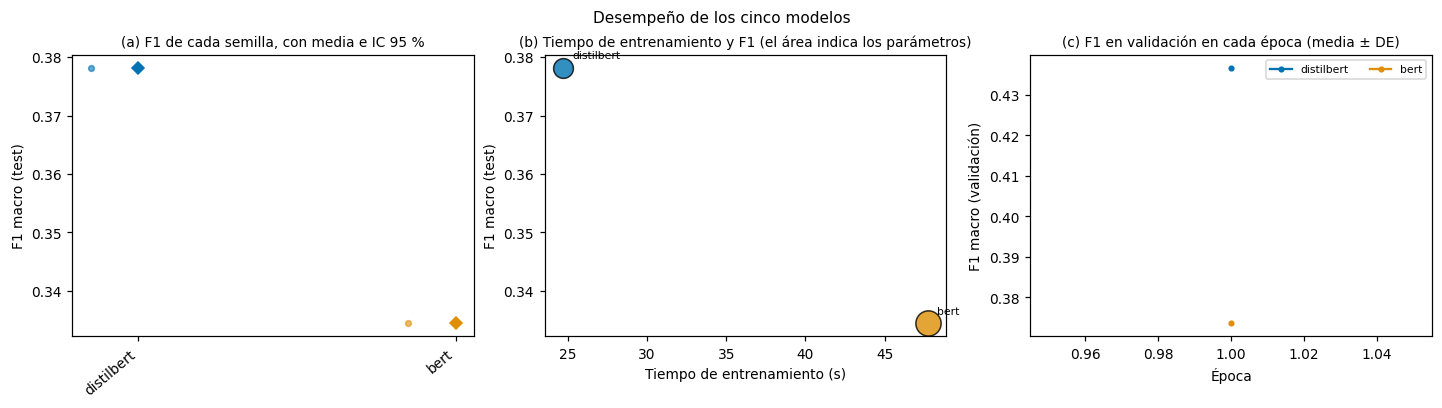

In [24]:
# Figura principal: F1 por semilla, costo frente a desempeño y F1 de validación por época
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for j, m in enumerate(order):
    f = df_main.loc[df_main.model == m, 'f1_macro'].values
    mu, h = ic_t(f)
    ax[0].errorbar(j, mu, yerr=None if np.isnan(h) else h, fmt='D', ms=6, capsize=4, color=pal[m])
    ax[0].scatter(j + np.linspace(-0.15, 0.15, len(f)), f, s=14, color=pal[m], alpha=0.6, zorder=3)
ax[0].set_xticks(range(len(order))); ax[0].set_xticklabels([short(m) for m in order], rotation=40, ha='right')
ax[0].set_ylabel('F1 macro (test)'); ax[0].set_title('(a) F1 de cada semilla, con media e IC 95 %')

for m in order:
    ax[1].scatter(mean.loc[m, 'train_s'], mean.loc[m, 'f1_macro'], s=mean.loc[m, 'params_m'] * 2.5,
                  color=pal[m], alpha=0.8, edgecolor='k')
    ax[1].annotate(short(m), (mean.loc[m, 'train_s'], mean.loc[m, 'f1_macro']),
                   textcoords='offset points', xytext=(6, 6), fontsize=7)
ax[1].set_xlabel('Tiempo de entrenamiento (s)'); ax[1].set_ylabel('F1 macro (test)')
ax[1].set_title('(b) Tiempo de entrenamiento y F1 (el área indica los parámetros)')

for m in order:
    ks = main_keys(m)
    h = np.array([[e['eval_f1_macro'] for e in RUNS[k]['history']] for k in ks])
    ax[2].errorbar(np.arange(1, h.shape[1] + 1), h.mean(0), yerr=h.std(0, ddof=1) if len(ks) > 1 else None,
                   marker='o', ms=3, capsize=2, color=pal[m], label=short(m))
ax[2].set_xlabel('Época'); ax[2].set_ylabel('F1 macro (validación)')
ax[2].set_title('(c) F1 en validación en cada época (media ± DE)'); ax[2].legend(ncol=2, fontsize=7)
fig.suptitle('Desempeño de los cinco modelos', fontsize=10)
fig.savefig(FIG_DIR + '/fig_comparacion.png'); plt.show()

Comparación pareada de los 1 pares de modelos en test (Δ = F1 del primero menos F1 del segundo)


,Δ F1 macro (pp),IC95 bootstrap (pp),p bootstrap pareado,p ajustado (Holm),Significativa
Comparación,,,,,
distilbert vs bert,+4.37,"[-6.25, 13.28]",0.4577,0.4577,no


Los IC no llevan corrección; la significancia sale del p ajustado con Holm, así que un IC sin el 0 puede no ser significativo.


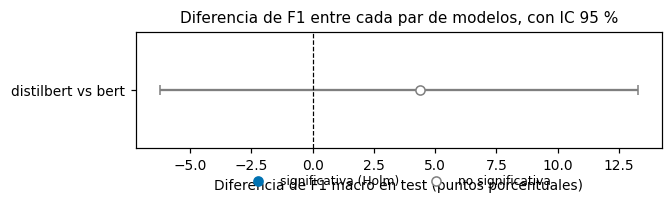

In [25]:
# Comparación de cada par de modelos con bootstrap pareado y corrección de Holm
from itertools import combinations
from matplotlib.lines import Line2D

pares = []
for a, b in combinations(order, 2):          # a va antes que b en el orden de validación
    d_obs = mean.loc[a, 'f1_macro'] - mean.loc[b, 'f1_macro']
    d = boot[a] - boot[b]                    # diferencia remuestreo a remuestreo
    lo, hi = np.percentile(d, [lo_q, hi_q])
    p = 2 * min((np.sum(d <= 0) + 1) / (B + 1), (np.sum(d >= 0) + 1) / (B + 1))
    pares.append(dict(a=a, b=b, d=d_obs, lo=lo, hi=hi, p=min(p, 1.0)))
p_adj = holm([r['p'] for r in pares])
for r, pa in zip(pares, p_adj):
    r['p_adj'] = pa
    r['sig'] = pa < CFG['alpha']

tab_pares = pd.DataFrame({
    'Comparación': [short(r['a']) + ' vs ' + short(r['b']) for r in pares],
    'Δ F1 macro (pp)': ['%+.2f' % (r['d'] * 100) for r in pares],
    'IC95 bootstrap (pp)': ['[%.2f, %.2f]' % (r['lo'] * 100, r['hi'] * 100) for r in pares],
    'p bootstrap pareado': [round(r['p'], 4) for r in pares],
    'p ajustado (Holm)': np.round(p_adj, 4),
    'Significativa': ['sí' if r['sig'] else 'no' for r in pares],
}).set_index('Comparación')
tab_pares.to_csv(OUT_DIR + '/comp_comparaciones_pareadas.csv')
print('Comparación pareada de los %d pares de modelos en test (Δ = F1 del primero menos F1 del segundo)' % len(pares))
display(tab_pares)
print('Los IC no llevan corrección; la significancia sale del p ajustado con Holm, así que un IC sin el 0 puede no ser significativo.')

# Figura de las diferencias con su IC
fig, ax = plt.subplots(figsize=(6, 0.34 * len(pares) + 1.4), constrained_layout=True)
for j, r in enumerate(pares):
    col = '#0072B2' if r['sig'] else '#7f7f7f'
    ax.errorbar(r['d'] * 100, j, xerr=[[(r['d'] - r['lo']) * 100], [(r['hi'] - r['d']) * 100]],
                fmt='o', capsize=3, color=col, mfc=col if r['sig'] else 'white')
ax.axvline(0, color='k', lw=0.8, ls='--')
ax.set_yticks(range(len(pares))); ax.set_yticklabels(tab_pares.index); ax.invert_yaxis()
ax.set_xlabel('Diferencia de F1 macro en test (puntos porcentuales)')
ax.legend(handles=[Line2D([0], [0], marker='o', color='#0072B2', ls='', label='significativa (Holm)'),
                   Line2D([0], [0], marker='o', color='#7f7f7f', mfc='white', ls='', label='no significativa')],
          loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
ax.set_title('Diferencia de F1 entre cada par de modelos, con IC 95 %', fontsize=10)
fig.savefig(FIG_DIR + '/fig_diferencias_pareadas.png'); plt.show()


### Diagnóstico de sobreajuste

Se compara la pérdida de entrenamiento con la de validación en cada época. La de entrenamiento es el promedio de la época con el dropout activo, y ambas incluyen el label smoothing, así que la brecha sirve para comparar modelos entre sí y no como valor absoluto. También se reporta en qué época cae el mejor checkpoint y cuánto F1 de validación se gana frente a quedarse con la última época.

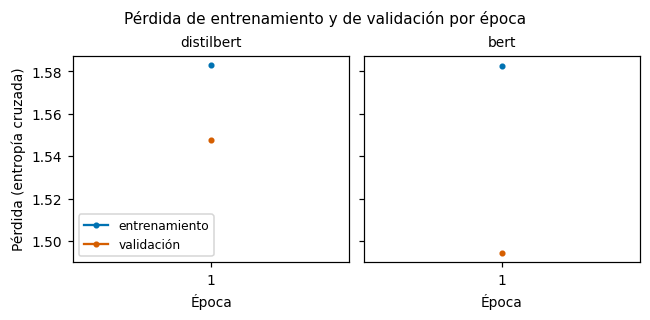

Sobreajuste por modelo (media ± DE entre semillas; las pérdidas incluyen label smoothing de 0.10)


,Pérdida entrenamiento (última época),Pérdida validación (última época),Brecha validación - entrenamiento,Época del mejor checkpoint (media),F1 val: mejor época - última (pp)
Modelo,,,,,
distilbert,1.583 ± 0.000,1.548 ± 0.000,-0.035 ± 0.000,1.0 de 1,0.00 ± 0.00
bert,1.582 ± 0.000,1.494 ± 0.000,-0.088 ± 0.000,1.0 de 1,0.00 ± 0.00


In [26]:
# Sobreajuste: pérdida de entrenamiento frente a validación en cada época
E = CFG['epochs']
tr_loss = {m: np.array([RUNS[k]['train_loss'][:E] for k in main_keys(m)]) for m in order}
va_loss = {m: np.array([[e['eval_loss'] for e in RUNS[k]['history']] for k in main_keys(m)]) for m in order}
va_f1 = {m: np.array([[e['eval_f1_macro'] for e in RUNS[k]['history']] for k in main_keys(m)]) for m in order}

def ms(x, f='%.3f'):
    x = np.asarray(x, dtype=float)
    return (f + ' ± ' + f) % (x.mean(), x.std(ddof=1) if len(x) > 1 else 0.0)

# Figura: una gráfica por modelo, con la banda de ± 1 DE entre semillas
ep = np.arange(1, E + 1)
fig, axes = plt.subplots(1, len(order), figsize=(2.9 * len(order), 2.8), sharey=True, constrained_layout=True)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, order):
    for arr, name, col in [(tr_loss[m], 'entrenamiento', '#0072B2'), (va_loss[m], 'validación', '#D55E00')]:
        mu = arr.mean(0)
        sd = arr.std(0, ddof=1) if len(arr) > 1 else np.zeros_like(mu)
        ax.plot(ep, mu, marker='o', ms=3, color=col, label=name)
        ax.fill_between(ep, mu - sd, mu + sd, color=col, alpha=0.2)
    ax.set_title(short(m)); ax.set_xlabel('Época'); ax.set_xticks(ep)
axes[0].set_ylabel('Pérdida (entropía cruzada)'); axes[0].legend()
fig.suptitle('Pérdida de entrenamiento y de validación por época', fontsize=10)
fig.savefig(FIG_DIR + '/fig_sobreajuste.png'); plt.show()

# Complementaria: tabla de sobreajuste
rows = []
for m in order:
    ganancia = (va_f1[m].max(1) - va_f1[m][:, -1]) * 100
    rows.append({'Modelo': short(m),
                 'Pérdida entrenamiento (última época)': ms(tr_loss[m][:, -1]),
                 'Pérdida validación (última época)': ms(va_loss[m][:, -1]),
                 'Brecha validación - entrenamiento': ms(va_loss[m][:, -1] - tr_loss[m][:, -1]),
                 'Época del mejor checkpoint (media)': '%.1f de %d' % (va_f1[m].argmax(1).mean() + 1, E),
                 'F1 val: mejor época - última (pp)': ms(ganancia, '%.2f')})
tab_sobre = pd.DataFrame(rows).set_index('Modelo')
tab_sobre.to_csv(OUT_DIR + '/comp_sobreajuste.csv')
print('Sobreajuste por modelo (media ± DE entre semillas; las pérdidas incluyen label smoothing de %.2f)' % CFG['label_smooth'])
display(tab_sobre)


### Resultados por categoría

Aquí se ve en qué categorías acierta cada modelo y con cuáles las confunde. Si dos categorías se confunden, conviene compararlo con la similitud TF-IDF de la sección 2.

F1 por categoría (media ± DE entre 1 semillas)


,business,entertainment,politics,sport,tech
Modelo,,,,,
distilbert,0.606 ± 0.000,0.000 ± 0.000,0.629 ± 0.000,0.656 ± 0.000,0.000 ± 0.000
bert,0.577 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.679 ± 0.000,0.417 ± 0.000


La categoría más fácil es sport (F1 0.6674) y la más difícil entertainment (F1 0.0000)


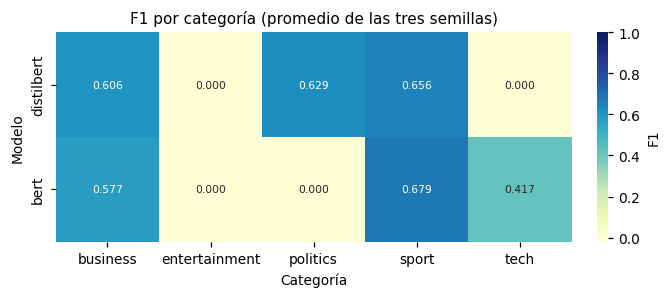

In [27]:
# F1 por categoría y modelo (media ± DE entre semillas)
pc_arr = {m: np.array([RUNS[k]['per_class_f1'] for k in main_keys(m)]) for m in order}
pc_df = pd.DataFrame({m: pc_arr[m].mean(0) for m in order}, index=labels).T
pc_df.index = [short(m) for m in order]
tab2 = pd.DataFrame({lab: [ms(pc_arr[m][:, c]) for m in order] for c, lab in enumerate(labels)},
                    index=[short(m) for m in order])
tab2.index.name = 'Modelo'
tab2.to_csv(OUT_DIR + '/tabla_f1_por_categoria.csv')
print('F1 por categoría (media ± DE entre %d semillas)' % len(CFG['seeds']))
display(tab2)
cls_mean = pc_df.mean(0).sort_values()
print('La categoría más fácil es %s (F1 %.4f) y la más difícil %s (F1 %.4f)'
      % (cls_mean.index[-1], cls_mean.iloc[-1], cls_mean.index[0], cls_mean.iloc[0]))

# Complementaria: heatmap de F1 por categoría
fig, ax = plt.subplots(figsize=(6, 0.5 * len(order) + 1.6), constrained_layout=True)
sns.heatmap(pc_df, annot=True, fmt='.3f', cmap='YlGnBu', vmin=round(pc_df.values.min() - 0.02, 2), vmax=1.0,
            cbar_kws={'label': 'F1'}, annot_kws={'size': 7}, ax=ax)
ax.set_xlabel('Categoría'); ax.set_ylabel('Modelo')
ax.set_title('F1 por categoría (promedio de las tres semillas)', fontsize=10)
fig.savefig(FIG_DIR + '/comp_f1_por_categoria_heatmap.png'); plt.show()


In [45]:
# Complementaria: precisión, recall y F1 por categoría de cada modelo, de mejor a peor F1
soporte = np.bincount(y_true, minlength=K)
tablas_cat = {}
for m in order:
    # semillas x (precisión, recall, F1) x categorías
    met = np.array([precision_recall_fscore_support(y_true, RUNS[k]['preds'], labels=list(range(K)), zero_division=0)[:3]
                    for k in main_keys(m)])
    t = pd.DataFrame({'Categoría': labels,
                      'Precisión': met[:, 0].mean(0),
                      'Recall': met[:, 1].mean(0),
                      'F1': met[:, 2].mean(0),
                      'DE F1': met[:, 2].std(0, ddof=1) if len(met) > 1 else 0.0,
                      'Soporte': soporte}).sort_values('F1', ascending=False).reset_index(drop=True)
    tablas_cat[m] = t
    print('%s (media de %d semillas)' % (short(m), len(met)))
    display(t.round(4))
    print('  Mejor categoría: %s (F1 %.4f). Peor: %s (F1 %.4f)\n'
          % (t['Categoría'].iloc[0], t['F1'].iloc[0], t['Categoría'].iloc[-1], t['F1'].iloc[-1]))

pd.concat(tablas_cat, names=['Modelo']).rename(index=short, level=0).to_csv(OUT_DIR + '/comp_metricas_por_categoria.csv')


distilbert (media de 1 semillas)


,Categoría,Precisión,Recall,F1,DE F1,Soporte
0,sport,0.4884,1.0,0.6562,0.0,21
1,politics,0.4583,1.0,0.6286,0.0,11
2,business,0.7692,0.5,0.6061,0.0,20
3,entertainment,0.0000,0.0,0.0000,0.0,16
4,tech,0.0000,0.0,0.0000,0.0,12


  Mejor categoría: sport (F1 0.6562). Peor: tech (F1 0.0000)

bert (media de 1 semillas)


,Categoría,Precisión,Recall,F1,DE F1,Soporte
0,sport,0.5429,0.9048,0.6786,0.0,21
1,business,0.4688,0.7500,0.5769,0.0,20
2,tech,0.4167,0.4167,0.4167,0.0,12
3,politics,0.0000,0.0000,0.0000,0.0,11
4,entertainment,0.0000,0.0000,0.0000,0.0,16


  Mejor categoría: sport (F1 0.6786). Peor: entertainment (F1 0.0000)



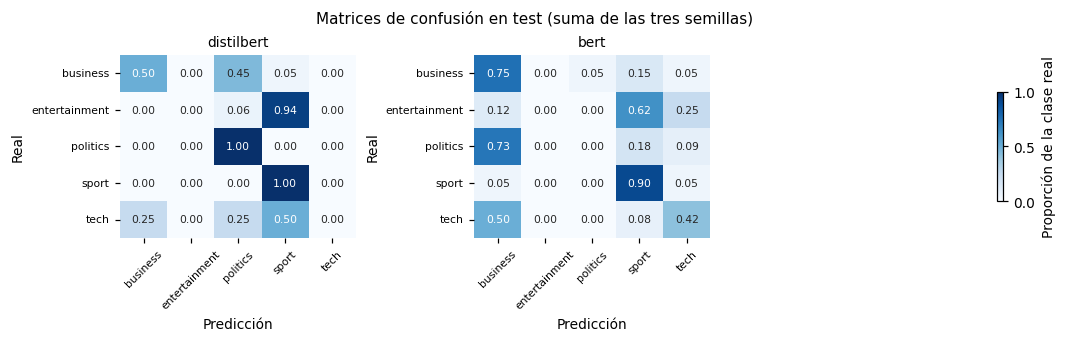

In [28]:
# Complementaria: matrices de confusión sumando las semillas; cada fila suma 1
n = len(order); ncols = 3; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.0 * nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)
for ax, m in zip(axes, order):
    cm = sum(confusion_matrix(y_true, RUNS[k]['preds'], labels=list(range(K))) for k in main_keys(m))
    sns.heatmap(cm / cm.sum(1, keepdims=True), ax=ax, vmin=0, vmax=1, cmap='Blues', cbar=False, annot=True,
                fmt='.2f', xticklabels=labels, yticklabels=labels, annot_kws={'size': 7})
    ax.set_title(short(m)); ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
    ax.tick_params(axis='x', rotation=45, labelsize=7); ax.tick_params(axis='y', labelsize=7)
for ax in axes[n:]:
    ax.axis('off')
fig.colorbar(plt.cm.ScalarMappable(cmap='Blues', norm=plt.Normalize(0, 1)), ax=axes.tolist(),
             shrink=0.6, label='Proporción de la clase real')
fig.suptitle('Matrices de confusión en test (suma de las tres semillas)', fontsize=10)
fig.savefig(FIG_DIR + '/comp_matrices_confusion.png'); plt.show()

## 7. Resultados cualitativos

Artículos concretos que el modelo de referencia clasifica bien y mal.

distilbert se equivoca en 38 de 80 artículos de test con esta semilla


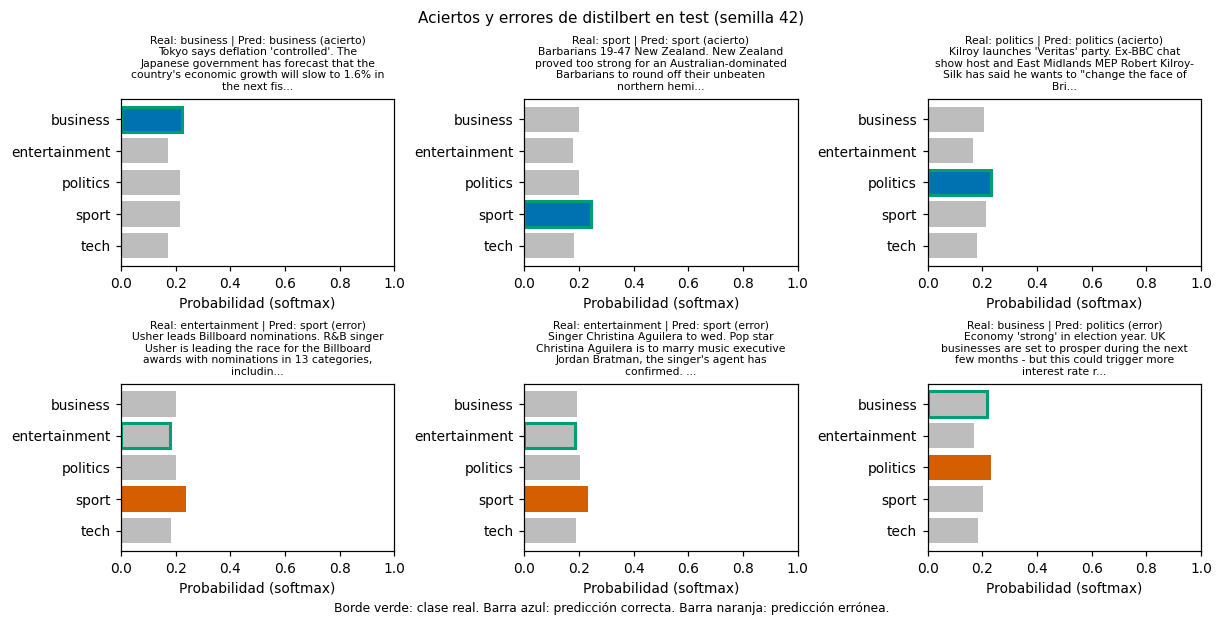

In [46]:
# Figura de ejemplos: 3 aciertos al azar y los 3 errores más confiados del modelo de referencia (semilla 42)
rb = RUNS[next((k for k in main_keys(BEST) if k[1] == 42), main_keys(BEST)[0])]   # semilla 42
probs, preds = rb['probs'], rb['preds']
conf = probs.max(1)
wrong = np.where(preds != y_true)[0]
right = np.where(preds == y_true)[0]
rng2 = np.random.default_rng(0)
sel_right = list(rng2.choice(right, size=min(3, len(right)), replace=False))
sel_wrong = list(wrong[np.argsort(-conf[wrong])][:3])
sel = sel_right + sel_wrong
print('%s se equivoca en %d de %d artículos de test con esta semilla' % (short(BEST), len(wrong), len(y_true)))

fig, axes = plt.subplots(2, 3, figsize=(11, 5.4), constrained_layout=True)
axes = axes.reshape(-1)
for ax, i in zip(axes, sel):
    ok = preds[i] == y_true[i]
    colors = ['#bdbdbd'] * K
    colors[preds[i]] = '#0072B2' if ok else '#D55E00'
    ax.barh(range(K), probs[i], color=colors,
            edgecolor=['#009E73' if j == y_true[i] else 'none' for j in range(K)], linewidth=2)
    ax.set_yticks(range(K)); ax.set_yticklabels(labels); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_xlabel('Probabilidad (softmax)')
    head = 'Real: %s | Pred: %s (%s)' % (labels[y_true[i]], labels[preds[i]], 'acierto' if ok else 'error')
    ax.set_title(head + '\n' + textwrap.fill(test_df['text'][i][:140] + '...', 46), fontsize=7)
for ax in axes[len(sel):]:
    ax.axis('off')
fig.text(0.5, -0.02, 'Borde verde: clase real. Barra azul: predicción correcta. Barra naranja: predicción errónea.',
         ha='center', fontsize=8)
fig.suptitle('Aciertos y errores de %s en test (semilla %d)' % (short(BEST), rb['seed']), fontsize=10)
fig.savefig(FIG_DIR + '/fig_ejemplos.png'); plt.show()

In [47]:
# Tabla de ejemplos con la misma semilla de la figura anterior:
# los 3 errores más confiados, los 2 menos confiados y 3 aciertos al azar
rb = RUNS[next((k for k in main_keys(BEST) if k[1] == 42), main_keys(BEST)[0])]   # semilla 42
pb, pd_ = rb['probs'], rb['preds']
conf = pb.max(1)
wrong = np.where(pd_ != y_true)[0]
right = np.where(pd_ == y_true)[0]
e_alta = list(wrong[np.argsort(-conf[wrong])][:3])
e_baja = [i for i in wrong[np.argsort(conf[wrong])] if i not in e_alta][:2]
aciertos = list(np.random.default_rng(0).choice(right, size=min(3, len(right)), replace=False))
sel3 = e_alta + e_baja + aciertos
fmt = lambda x: ('%.3f' % x).replace('.', ',')
tab3 = pd.DataFrame({
    'Inicio del artículo': ['"' + test_df['text'][i][:45].rstrip() + '..."' for i in sel3],
    'Categoría real': [labels[y_true[i]] for i in sel3],
    'Predicción': [labels[pd_[i]] for i in sel3],
    'Prob. predicha': [fmt(pb[i, pd_[i]]) for i in sel3],
    'Prob. real': [fmt(pb[i, y_true[i]]) for i in sel3],
})
tab3.to_csv(OUT_DIR + '/tabla_ejemplos.csv', index=False)
print('Ejemplos de test clasificados por %s (semilla %d)' % (short(BEST), rb['seed']))
pd.set_option('display.max_colwidth', 60)
display(tab3)
print('Prob. es la probabilidad softmax de la clase. Con label smoothing de 0,1 la máxima ronda 0,92.')

Ejemplos de test clasificados por distilbert (semilla 42)


,Inicio del artículo,Categoría real,Predicción,Prob. predicha,Prob. real
0,"""Usher leads Billboard nominations. R&B singer...""",entertainment,sport,"0,236","0,181"
1,"""Singer Christina Aguilera to wed. Pop star Ch...""",entertainment,sport,"0,231","0,184"
2,"""Economy 'strong' in election year. UK busines...""",business,politics,"0,230","0,215"
3,"""Voters flock to blog awards site. Voting is u...""",tech,politics,"0,210","0,198"
4,"""Screensaver tackles spam websites. Net users...""",tech,sport,"0,210","0,199"
5,"""Tokyo says deflation 'controlled'. The Japane...""",business,business,"0,224","0,224"
6,"""Barbarians 19-47 New Zealand. New Zealand pro...""",sport,sport,"0,245","0,245"
7,"""Kilroy launches 'Veritas' party. Ex-BBC chat...""",politics,politics,"0,233","0,233"


Prob. es la probabilidad softmax de la clase. Con label smoothing de 0,1 la máxima ronda 0,92.


In [31]:
# Complementaria: los artículos de test en los que más fallan los modelos, con el voto de cada uno
all_keys = [k for m in order for k in main_keys(m)]
fail = np.mean([RUNS[k]['preds'] != y_true for k in all_keys], axis=0)
rows = []
for i in np.argsort(-fail)[:8]:
    row = {'Texto': test_df['text'][i][:90] + '...', 'Real': labels[y_true[i]], 'Tasa de fallo': round(fail[i], 2)}
    for m in order:
        votes = np.array([RUNS[k]['preds'][i] for k in main_keys(m)])
        row[short(m)] = labels[np.bincount(votes, minlength=K).argmax()]
    rows.append(row)
tab_dificiles = pd.DataFrame(rows)
tab_dificiles.to_csv(OUT_DIR + '/comp_ejemplos_dificiles.csv', index=False)
pd.set_option('display.max_colwidth', 100)
display(tab_dificiles)

,Texto,Real,Tasa de fallo,distilbert,bert
0,Fockers fuel festive film chart Comedy Meet The Fockers topped the festive box office in N...,entertainment,1.0,sport,tech
1,Usher leads Billboard nominations R&B singer Usher is leading the race for the Billboard a...,entertainment,1.0,sport,sport
2,"Snow Patrol bassist exits group Snow Patrol had ""no other course of action"" but to ask the...",entertainment,1.0,sport,sport
3,"Brits debate over 'urban' music Joss Stone, a 17-year-old soul singer from Devon, beat Diz...",entertainment,1.0,sport,tech
4,"REM announce new Glasgow concert US band REM have announced plans to perform for 10,000 Sc...",entertainment,1.0,sport,sport
5,Little Britain vies for TV trophy BBC hits Little Britain and Strictly Come Dancing are am...,entertainment,1.0,sport,business
6,US bank boss hails 'genius' Smith US Federal Reserve chairman Alan Greenspan has given a s...,business,1.0,politics,sport
7,Learning to love broadband We are reaching the point where broadband is a central part of ...,tech,1.0,sport,sport


### Análisis de errores (complementario)

Se toman los artículos de test que el modelo de referencia clasifica mal (por voto entre sus 3 semillas) y se agrupan según su causa más probable:

- Consenso entre modelos: al menos el 80 % de las corridas de todos los modelos predice la misma clase equivocada. Suele ser una etiqueta dudosa o un artículo que mezcla dos temas.
- Frontera entre dos clases: la probabilidad de la clase predicha y la de la real difieren en menos de 0,25.
- Error confiado y propio del modelo: falla con probabilidad de al menos 0,7 y los demás modelos no coinciden en el error.
- Otro: el resto.

También se marca si el artículo se trunca a 256 tokens y si está entre el 10 % más corto del test. Estas reglas son un primer filtro. Para el informe hay que leer los textos en el CSV y anotar la causa en la columna `revision_manual` (por ejemplo, "mezcla business y tech" o "etiqueta discutible").

In [32]:
# Complementaria: errores del modelo de referencia agrupados por causa probable.
# Un artículo cuenta como error si el voto de las 3 semillas no acierta
ks = main_keys(BEST)
P = np.stack([RUNS[k]['preds'] for k in ks])
vote = np.array([np.bincount(P[:, i], minlength=K).argmax() for i in range(P.shape[1])])
pr = np.mean([RUNS[k]['probs'] for k in ks], axis=0)          # probabilidad promedio de las semillas
err = np.where(vote != y_true)[0]

# acuerdo = proporción de corridas (de todos los modelos) que dan la misma clase equivocada
all_preds = np.stack([RUNS[k]['preds'] for m in order for k in main_keys(m)])
n_tok_test = np.array([len(x) for x in tok_ref(test_df['text'].tolist(), truncation=False)['input_ids']])
n_pal = test_df['text'].str.split().str.len().values
p_corto = np.percentile(n_pal, 10)                           # corto = entre el 10 % más corto del test

rows = []
for i in err:
    p_pred, p_real = pr[i, vote[i]], pr[i, y_true[i]]
    acuerdo = (all_preds[:, i] == vote[i]).mean()
    if acuerdo >= 0.8:
        cat = 'Consenso entre modelos'
    elif p_pred - p_real < 0.25:
        cat = 'Frontera entre dos clases'
    elif p_pred >= 0.7:
        cat = 'Error confiado y propio del modelo'
    else:
        cat = 'Otro'
    rows.append({'idx_test': int(i), 'real': labels[y_true[i]], 'pred': labels[vote[i]],
                 'p_pred': round(p_pred, 2), 'p_real': round(p_real, 2), 'acuerdo_modelos': round(acuerdo, 2),
                 'categoria_auto': cat, 'truncado': bool(n_tok_test[i] > CFG['max_len']),
                 'corto': bool(n_pal[i] <= p_corto), 'texto': test_df['text'][i][:300],
                 'revision_manual': ''})
tab_err = pd.DataFrame(rows)
tab_err.to_csv(OUT_DIR + '/comp_errores_categorias.csv', index=False)

print('%s falla en %d de %d artículos de test (voto de sus %d semillas)' % (short(BEST), len(err), len(y_true), len(ks)))
if len(tab_err):
    res = tab_err.groupby('categoria_auto').size().rename('errores').to_frame()
    res['%'] = (100 * res['errores'] / len(tab_err)).round(1)
    display(res.sort_values('errores', ascending=False))
    display(pd.crosstab(tab_err['real'], tab_err['pred'], rownames=['real'], colnames=['predicha']))
    # se compara con el test completo para ver si los truncados o los cortos fallan más
    print('Artículos truncados: %.0f%% de los errores frente a %.0f%% del test' % (100 * tab_err['truncado'].mean(), 100 * (n_tok_test > CFG['max_len']).mean()))
    print('Artículos cortos:    %.0f%% de los errores frente a %.0f%% del test' % (100 * tab_err['corto'].mean(), 100 * (n_pal <= p_corto).mean()))
    pd.set_option('display.max_colwidth', 110)
    display(tab_err.sort_values(['categoria_auto', 'p_pred'], ascending=[True, False])
            [['real', 'pred', 'p_pred', 'acuerdo_modelos', 'categoria_auto', 'texto']].head(10))
    print('La lista completa está en %s; la columna revision_manual se llena a mano' % (OUT_DIR + '/comp_errores_categorias.csv'))

distilbert falla en 38 de 80 artículos de test (voto de sus 1 semillas)


,errores,%
categoria_auto,,
Frontera entre dos clases,26,68.4
Consenso entre modelos,12,31.6


predicha,business,politics,sport
real,,,
business,0,9,1
entertainment,0,1,15
tech,3,3,6


Artículos truncados: 100% de los errores frente a 100% del test
Artículos cortos:    11% de los errores frente a 10% del test


,real,pred,p_pred,acuerdo_modelos,categoria_auto,texto
5,entertainment,sport,0.24,1.0,Consenso entre modelos,Usher leads Billboard nominations R&B singer Usher is leading the race for the Billboard awards with nomin...
9,entertainment,sport,0.23,1.0,Consenso entre modelos,"REM announce new Glasgow concert US band REM have announced plans to perform for 10,000 Scottish fans in a..."
13,entertainment,sport,0.23,1.0,Consenso entre modelos,DVD review: Harry Potter and the Prisoner of Azkaban This third Harry Potter film brought a change of dire...
37,business,politics,0.23,1.0,Consenso entre modelos,Call to save manufacturing jobs The Trades Union Congress (TUC) is calling on the government to stem job l...
4,entertainment,sport,0.22,1.0,Consenso entre modelos,"Snow Patrol bassist exits group Snow Patrol had ""no other course of action"" but to ask their co-founder an..."
11,tech,sport,0.22,1.0,Consenso entre modelos,"Learning to love broadband We are reaching the point where broadband is a central part of daily life, at l..."
16,entertainment,sport,0.22,1.0,Consenso entre modelos,"Stars pay tribute to actor Davis Hollywood stars including Spike Lee, Burt Reynolds and Oscar nominee Alan..."
23,entertainment,sport,0.22,1.0,Consenso entre modelos,US TV special for tsunami relief A US television network will screen a celebrity TV special to benefit the...
24,entertainment,sport,0.22,1.0,Consenso entre modelos,"Spirit awards hail Sideways The comedy Sideways has dominated this year's Independent Spirit Awards, winni..."
27,entertainment,sport,0.22,1.0,Consenso entre modelos,Incredibles win animation awards The Incredibles movie has beaten Shrek 2 to the main prizes at Hollywood'...


La lista completa está en results/comp_errores_categorias.csv; la columna revision_manual se llena a mano


## 8. Sensibilidad a la longitud máxima y a la regularización

Sobre el modelo de referencia se cambia un factor a la vez, con el resto en su valor base y las mismas tres semillas: longitud máxima (128 y 512 tokens), tasa de aprendizaje (1e-5 y 5e-5), weight decay (0 y 0,1) y label smoothing (0). Las configuraciones se comparan con el F1 macro de validación; el de test aparece solo como referencia. Con tres semillas los intervalos son anchos, así que solo se comentan las diferencias grandes.

distilbert max_len 128 lr 2e-05 wd 0.01 ls 0.1 semilla 42  f1 0.3782
distilbert max_len 64 lr 2e-05 wd 0.01 ls 0.1 semilla 42  f1 0.3350
distilbert max_len 128 lr 1e-05 wd 0.01 ls 0.1 semilla 42  f1 0.2532
distilbert max_len 128 lr 5e-05 wd 0.01 ls 0.1 semilla 42  f1 0.4256
distilbert max_len 128 lr 2e-05 wd 0 ls 0.1 semilla 42  f1 0.3782
distilbert max_len 128 lr 2e-05 wd 0.1 ls 0.1 semilla 42  f1 0.3799
distilbert max_len 128 lr 2e-05 wd 0.01 ls 0 semilla 42  f1 0.3818
(a) Longitud máxima (tokens)


,F1 val (%),IC95 t (val),F1 test (%),Entrenamiento (s)
max_len,,,,
64,35.10 ± 0.00,"[nan, nan]",33.50,13
128,43.67 ± 0.00,"[nan, nan]",37.82,25


(b) Tasa de aprendizaje


,F1 val (%),IC95 t (val),F1 test (%),Entrenamiento (s)
lr,,,,
0.00001,26.24 ± 0.00,"[nan, nan]",25.32,22
0.00002,43.67 ± 0.00,"[nan, nan]",37.82,25
0.00005,60.13 ± 0.00,"[nan, nan]",42.56,25


(c) Weight decay


,F1 val (%),IC95 t (val),F1 test (%),Entrenamiento (s)
wd,,,,
0.00,43.67 ± 0.00,"[nan, nan]",37.82,25
0.01,43.67 ± 0.00,"[nan, nan]",37.82,25
0.10,43.67 ± 0.00,"[nan, nan]",37.99,26


(d) Label smoothing


,F1 val (%),IC95 t (val),F1 test (%),Entrenamiento (s)
ls,,,,
0.0,43.67 ± 0.00,"[nan, nan]",38.18,23
0.1,43.67 ± 0.00,"[nan, nan]",37.82,25


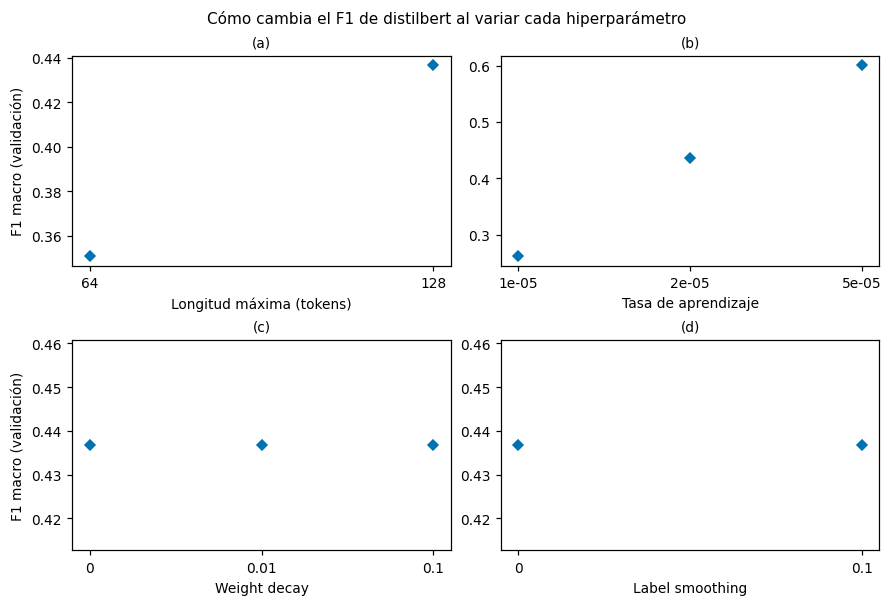

In [33]:
# Se cambia un hiperparámetro a la vez sobre el modelo de referencia
if RUN_ABLATION:
    base = dict(max_len=CFG['max_len'], lr=CFG['lr'], wd=CFG['weight_decay'], ls=CFG['label_smooth'])
    levels = {'max_len': [64] if DEBUG else [128, 512],
              'lr': [1e-5, 5e-5],
              'wd': [0.0, 0.1],
              'ls': [0.0]}
    configs = [dict(base)]
    for f, vals in levels.items():
        for v in vals:
            c = dict(base); c[f] = v
            configs.append(c)
    for c in configs:
        for s in CFG['seeds']:
            try:
                r = run_one(BEST, s, c['max_len'], c['lr'], c['wd'], c['ls'])
                print('%s max_len %d lr %g wd %g ls %g semilla %d  f1 %.4f' % (short(BEST), c['max_len'], c['lr'], c['wd'], c['ls'], s, r['f1_macro']))
            except Exception as e:
                print('Falló la configuración %s con semilla %d: %s' % (c, s, repr(e)[:200]))

    dfa = runs_df(models=[BEST], seeds=CFG['seeds'])

    def slice_(factor):
        d = dfa
        for k, v in base.items():
            if k != factor:
                d = d[d[k] == v]
        return d

    def resumen(d, col):
        out = []
        for v, g in d.groupby(col):
            mu, h = ic_t(g['val_f1'].values)
            sd = g['val_f1'].std(ddof=1) if len(g) > 1 else 0.0
            out.append({col: v, 'F1 val (%)': '%.2f ± %.2f' % (mu * 100, sd * 100),
                        'IC95 t (val)': '[%.2f, %.2f]' % ((mu - h) * 100, (mu + h) * 100),
                        'F1 test (%)': round(g['f1_macro'].mean() * 100, 2),
                        'Entrenamiento (s)': round(g['train_s'].mean())})
        return pd.DataFrame(out).set_index(col)

    nombres = {'max_len': 'Longitud máxima (tokens)', 'lr': 'Tasa de aprendizaje',
               'wd': 'Weight decay', 'ls': 'Label smoothing'}
    # Complementaria: una tabla y una gráfica por hiperparámetro
    fig, axes = plt.subplots(2, 2, figsize=(8, 5.4), constrained_layout=True)
    for ax, (f, titulo), letra in zip(axes.reshape(-1), nombres.items(), 'abcd'):
        d = slice_(f)
        tabla = resumen(d, f)
        tabla.to_csv(OUT_DIR + '/comp_sensibilidad_%s.csv' % f)
        print('(%s) %s' % (letra, titulo)); display(tabla)
        vals = sorted(d[f].unique())
        for j, v in enumerate(vals):
            fv = d.loc[d[f] == v, 'val_f1'].values
            mu, h = ic_t(fv)
            ax.scatter(np.full(len(fv), j), fv, s=12, color='#0072B2', alpha=0.4)
            ax.errorbar(j, mu, yerr=None if np.isnan(h) else h, fmt='D', ms=5, capsize=4, color='#0072B2')
        ax.set_xticks(range(len(vals))); ax.set_xticklabels(['%g' % v for v in vals])
        ax.set_xlabel(titulo); ax.set_title('(%s)' % letra)
        if letra in 'ac':
            ax.set_ylabel('F1 macro (validación)')
    fig.suptitle('Cómo cambia el F1 de %s al variar cada hiperparámetro' % short(BEST), fontsize=10)
    fig.savefig(FIG_DIR + '/comp_sensibilidad.png'); plt.show()


## 9. Cifras para el reporte

Resumen de los números que se citan en el informe. Al final se comprimen las figuras en `figuras_y_tablas.zip`.

In [34]:
# Cifras del modelo de referencia y de las comparaciones
b = mean.loc[BEST]
mu, h = ic_t(df_main.loc[df_main.model == BEST, 'f1_macro'].values)
lo, hi = np.percentile(boot[BEST], [lo_q, hi_q])
print('%d modelos, semillas %s, %d artículos de test' % (len(order), CFG['seeds'], len(y_true)))
print('Modelo de referencia (elegido en validación):', short(BEST))
print('  F1 macro en test: %.2f ± %.2f' % (b.f1_macro * 100, std.loc[BEST, 'f1_macro'] * 100))
print('  IC 95 %% entre semillas (t): [%.2f, %.2f]' % ((mu - h) * 100, (mu + h) * 100))
print('  IC 95 %% bootstrap en test: [%.2f, %.2f]' % (lo * 100, hi * 100))
for r in pares:
    if r['a'] == BEST:
        print('  %s vs %-12s ΔF1 %+.2f pp, p ajustado (Holm) %.4f' % (short(BEST), short(r['b']), r['d'] * 100, r['p_adj']))
print('  Diferencias significativas (Holm, α = %.2f): %d de %d pares' % (CFG['alpha'], sum(r['sig'] for r in pares), len(pares)))
print('Categoría más fácil: %s; más difícil: %s' % (cls_mean.index[-1], cls_mean.index[0]))
print('  Brecha de pérdida validación − entrenamiento en la última época:', ms(va_loss[BEST][:, -1] - tr_loss[BEST][:, -1]))
print('  El mejor checkpoint cae en promedio en la época %.1f de %d' % (va_f1[BEST].argmax(1).mean() + 1, E))
if DEBUG:
    print('Modo DEBUG activo: estas cifras no sirven para el informe')
shutil.make_archive('figuras_y_tablas', 'zip', '.', FIG_DIR)

2 modelos, semillas [42], 80 artículos de test
Modelo de referencia (elegido en validación): distilbert
  F1 macro en test: 37.82 ± 0.00
  IC 95 % entre semillas (t): [nan, nan]
  IC 95 % bootstrap en test: [30.44, 42.68]
  distilbert vs bert         ΔF1 +4.37 pp, p ajustado (Holm) 0.4577
  Diferencias significativas (Holm, α = 0.05): 0 de 1 pares
Categoría más fácil: sport; más difícil: entertainment
  Brecha de pérdida validación − entrenamiento en la última época: -0.035 ± 0.000
  El mejor checkpoint cae en promedio en la época 1.0 de 1
Modo DEBUG activo: estas cifras no sirven para el informe


'c:\\Users\\CO52842942\\Documents\\MAIA\\Tecnicas_Deep_Learning\\Microproyecto3\\Transformer\\figuras_y_tablas.zip'

## Referencias

[1] J. Devlin, M.-W. Chang, K. Lee and K. Toutanova, "BERT: Pre-training of deep bidirectional transformers for language understanding," in *Proc. NAACL-HLT*, 2019, pp. 4171-4186.

[2] Y. Liu *et al.*, "RoBERTa: A robustly optimized BERT pretraining approach," arXiv:1907.11692, 2019.

[3] V. Sanh, L. Debut, J. Chaumond and T. Wolf, "DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter," arXiv:1910.01108, 2019.

[4] K. Clark, M.-T. Luong, Q. V. Le and C. D. Manning, "ELECTRA: Pre-training text encoders as discriminators rather than generators," in *Proc. ICLR*, 2020.

[5] P. He, J. Gao and W. Chen, "DeBERTaV3: Improving DeBERTa using ELECTRA-style pre-training with gradient-disentangled embedding sharing," in *Proc. ICLR*, 2023.

[6] D. Greene and P. Cunningham, "Practical solutions to the problem of diagonal dominance in kernel document clustering," in *Proc. ICML*, 2006, pp. 377-384.

[7] T. Wolf *et al.*, "Transformers: State-of-the-art natural language processing," in *Proc. EMNLP: System Demonstrations*, 2020, pp. 38-45.

[8] B. Efron and R. J. Tibshirani, *An Introduction to the Bootstrap*. New York, NY, USA: Chapman & Hall, 1993.

[9] T. Berg-Kirkpatrick, D. Burkett and D. Klein, "An empirical investigation of statistical significance in NLP," in *Proc. EMNLP-CoNLL*, 2012, pp. 995-1005.

[10] R. Dror, G. Baumer, S. Shlomov and R. Reichart, "The hitchhiker's guide to testing statistical significance in natural language processing," in *Proc. ACL*, 2018, pp. 1383-1392.

[11] J. Dodge *et al.*, "Fine-tuning pretrained language models: Weight initializations, data orders, and early stopping," arXiv:2002.06305, 2020.

[12] M. Mosbach, M. Andriushchenko and D. Klakow, "On the stability of fine-tuning BERT: Misconceptions, explanations, and strong baselines," in *Proc. ICLR*, 2021.

[13] S. Holm, "A simple sequentially rejective multiple test procedure," *Scand. J. Statist.*, vol. 6, no. 2, pp. 65-70, 1979.

[14] C. Szegedy, V. Vanhoucke, S. Ioffe, J. Shlens and Z. Wojna, "Rethinking the Inception architecture for computer vision," in *Proc. IEEE CVPR*, 2016, pp. 2818-2826.

[15] I. Loshchilov and F. Hutter, "Decoupled weight decay regularization," in *Proc. ICLR*, 2019.

[16] N. Srivastava, G. Hinton, A. Krizhevsky, I. Sutskever and R. Salakhutdinov, "Dropout: A simple way to prevent neural networks from overfitting," *J. Mach. Learn. Res.*, vol. 15, no. 56, pp. 1929-1958, 2014.